# 03 — Feature Engineering : de l'image au vecteur numérique

Un algorithme comme KNN, SVM ou Random Forest ne sait pas lire une image : il attend **une ligne de nombres de longueur fixe**.
Ce notebook explique comment chaque zone endommagée devient un vecteur, et **mesure** quels choix améliorent réellement le résultat.

```
photo + bbox  ->  découpe  ->  patch 128×128  ->  [ HOG | couleur | texture ]  ->  vecteur de 1840 nombres
```

**Règles respectées**
- Code réutilisable dans `src/features/` (`preprocessing.py`, `extractors.py`, `build_dataset.py`) : **le même code servira à l'API**.
- Chaque choix est comparé sur la **validation propre** (sans quasi-doublons). **Le test n'est jamais utilisé.**
- Pour comparer les choix, on utilise deux classifieurs « sondes » à réglages **fixes** (SVM linéaire et Random Forest).
  Ce ne sont pas les modèles finaux : la comparaison KNN / SVM / Random Forest et le réglage des hyperparamètres sont l'objet de la phase 4.

Durée d'exécution : environ 15 minutes (les descripteurs déjà calculés sont réutilisés depuis `data/processed/`).

In [1]:
import sys, time, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog, local_binary_pattern
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score

from src.data.coco_loader import image_dir
from src.data.image_io import read_image_rgb
from src.features.preprocessing import PreprocessConfig, crop_region, preprocess_region
from src.features.extractors import FeatureConfig, extract_feature_blocks
from src.features.build_dataset import load_regions, build_and_save, load_features, config_tag

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
CLASS_ORDER = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
regions = load_regions()
print(f"{len(regions)} régions utilisables (reports/cleaning/regions.csv, keep == True)")
print(regions.groupby("split").size().to_dict())

8740 régions utilisables (reports/cleaning/regions.csv, keep == True)
{'test': 785, 'train': 6211, 'val': 1744}


## 1. Étape par étape : une région devient un patch

1. **Découpe** de la bbox dans la photo originale (pleine résolution).
2. **Redimensionnement** en un carré de taille fixe (128 × 128) : tous les vecteurs doivent avoir la même longueur,
   et les photos de l'application n'auront pas la même résolution que celles du dataset.
3. **Conversion de couleurs** : niveaux de gris pour la forme et la texture, HSV et Lab pour la couleur.

La configuration ci-dessous (taille 128, sans marge, mode *stretch*) est celle retenue à la section 4.

Configuration retenue : PreprocessConfig(patch_size=128, margin=0.0, resize_mode='stretch')


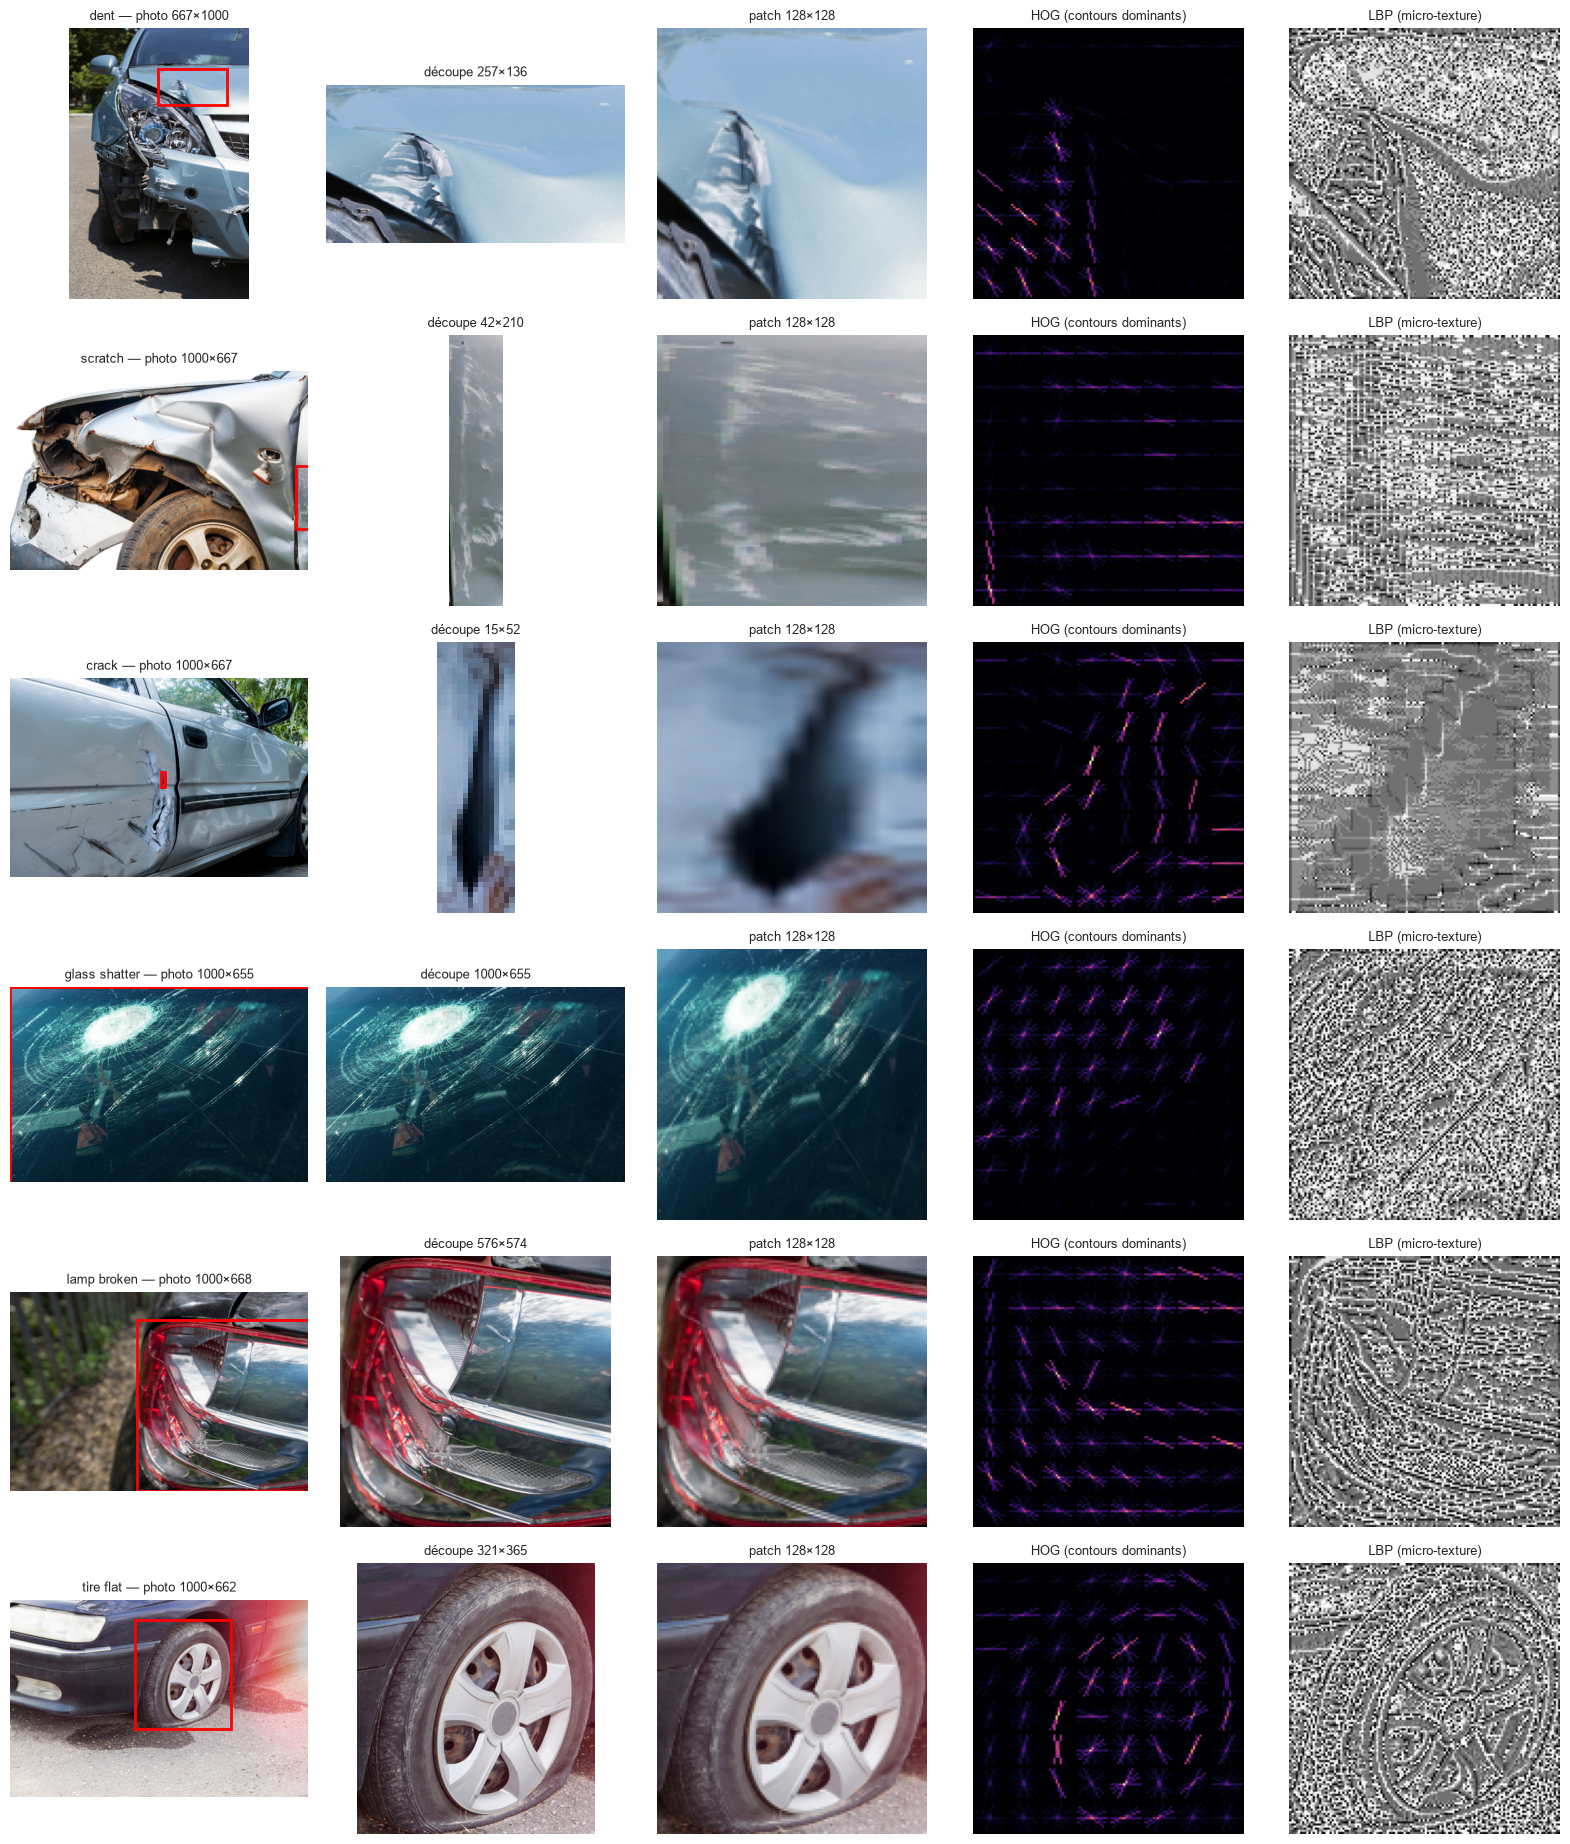

In [2]:
cfg = PreprocessConfig()
print("Configuration retenue :", cfg)
examples = regions[regions["split"] == "train"].groupby("category_name").sample(1, random_state=3).set_index("category_name").loc[CLASS_ORDER]

fig, axes = plt.subplots(len(examples), 5, figsize=(16, 3.1 * len(examples)))
for row, (cls, r) in zip(axes, examples.iterrows()):
    img = read_image_rgb(image_dir(r["split"]) / r["file_name"])
    bbox = (r["bbox_x"], r["bbox_y"], r["bbox_w"], r["bbox_h"])
    crop = crop_region(img, bbox, cfg.margin)
    patch = preprocess_region(crop, cfg)
    gray = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    row[0].imshow(img); row[0].add_patch(plt.Rectangle(bbox[:2], bbox[2], bbox[3], fill=False, ec="red", lw=2))
    row[0].set_title(f"{cls} — photo {img.shape[1]}×{img.shape[0]}", fontsize=9)
    row[1].imshow(crop); row[1].set_title(f"découpe {crop.shape[1]}×{crop.shape[0]}", fontsize=9)
    row[2].imshow(patch); row[2].set_title("patch 128×128", fontsize=9)
    row[3].imshow(hog_img, cmap="magma"); row[3].set_title("HOG (contours dominants)", fontsize=9)
    row[4].imshow(lbp, cmap="gray"); row[4].set_title("LBP (micro-texture)", fontsize=9)
    for ax in row: ax.axis("off")
plt.tight_layout(); plt.show()

**Interprétation.** La découpe isole le dommage ; le patch lui donne une taille fixe. La carte HOG montre l'orientation dominante des contours
dans chaque cellule (lignes nettes d'une rayure, contour circulaire d'un pneu, réseau de fissures d'un pare-brise) ; la carte LBP révèle la micro-texture
(surface lisse de la carrosserie contre surface granuleuse ou fissurée).

## 2. Les trois familles de descripteurs

| Bloc | Ce qu'il mesure | Calcul | Dimension |
|---|---|---|---|
| **HOG** | forme et contours | gradients du patch en gris ; 8×8 cellules de 16 px ; histogramme de 9 orientations par cellule ; normalisation par blocs de 2×2 cellules (7×7 blocs × 4 cellules × 9) | 1764 |
| **Couleur** | teinte, saturation, luminosité | histogrammes HSV (18 + 8 + 8 cases, normalisés) + moyenne et écart-type des 3 canaux Lab | 40 |
| **Texture** | rugosité, régularité | histogrammes LBP uniformes à 2 échelles (P=8, R=1 → 10 ; P=16, R=2 → 18) + 4 statistiques de Haralick (GLCM : contraste, homogénéité, énergie, corrélation) à 2 distances | 36 |
| **Total** | | concaténation | **1840** |

Ces calculs **n'apprennent rien des données** : ils sont identiques pour chaque image. L'extraction ne peut donc pas créer de fuite de données ;
seules les transformations apprises (normalisation, PCA) devront être ajustées sur le train uniquement (section 6).

hog     :  1764 valeurs, min=0.000, max=0.433, premières : [0.225 0.259 0.259 0.259 0.259]
color   :    40 valeurs, min=0.000, max=0.865, premières : [0.005 0.    0.    0.001 0.001]
texture :    36 valeurs, min=0.020, max=8.680, premières : [0.04  0.07  0.035 0.096 0.163]
Vecteur final : 1840 nombres


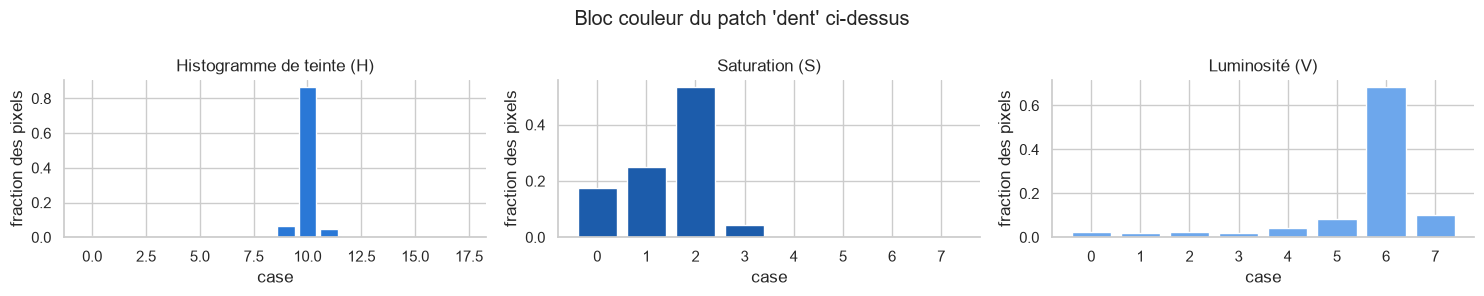

In [3]:
patch = preprocess_region(crop_region(read_image_rgb(image_dir("train") / examples.loc["dent", "file_name"]),
                                      tuple(examples.loc["dent", ["bbox_x", "bbox_y", "bbox_w", "bbox_h"]]), 0.0))
blocks = extract_feature_blocks(patch)
for b, v in blocks.items():
    print(f"{b:8s}: {v.shape[0]:5d} valeurs, min={v.min():.3f}, max={v.max():.3f}, premières : {np.round(v[:5], 3)}")
print("Vecteur final :", sum(v.shape[0] for v in blocks.values()), "nombres")

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
c = blocks["color"]
axes[0].bar(range(18), c[:18], color="#2a78d6"); axes[0].set_title("Histogramme de teinte (H)")
axes[1].bar(range(8), c[18:26], color="#1c5cab"); axes[1].set_title("Saturation (S)")
axes[2].bar(range(8), c[26:34], color="#6da7ec"); axes[2].set_title("Luminosité (V)")
for ax in axes: ax.set_xlabel("case"); ax.set_ylabel("fraction des pixels")
plt.suptitle("Bloc couleur du patch 'dent' ci-dessus"); plt.tight_layout(); plt.show()

## 3. Construction de X et y

`build_and_save` lit chaque photo **une seule fois**, découpe toutes ses régions, calcule les descripteurs (en parallèle avec joblib)
et enregistre le résultat dans `data/processed/features_<config>.npz` (non versionné, régénérable en ≈ 30 s).

In [4]:
path = build_and_save(cfg)
blocks, y, meta, configs = load_features(path)
X = np.hstack([blocks[b] for b in ("hog", "color", "texture")])
print("Fichier :", path.relative_to(PROJECT_ROOT))
print("X :", X.shape, X.dtype, "| y :", y.shape, "| valeurs manquantes :", int(np.isnan(X).sum()))
print("Configs enregistrées :", configs["preprocess"])
TRAIN = (meta["split"] == "train").to_numpy()
VAL = ((meta["split"] == "val") & meta["image_eval_keep"]).to_numpy()     # validation PROPRE
print(f"train : {TRAIN.sum()} régions | validation propre : {VAL.sum()} régions | test : non utilisé")

Fichier : data\processed\features_s128_m00_stretch.npz
X : (8740, 1840) float32 | y : (8740,) | valeurs manquantes : 0
Configs enregistrées : {'patch_size': 128, 'margin': 0.0, 'resize_mode': 'stretch'}
train : 6211 régions | validation propre : 1666 régions | test : non utilisé


## 4. Choix du prétraitement (mesurés sur la validation propre)

Questions : faut-il ajouter une **marge de contexte** autour de la bbox ? **Garder les proportions** (pad) ou **déformer** (stretch) ?
Quelle **taille** de patch ? Chaque configuration est extraite, puis évaluée par les deux sondes (F1 macro, sur la validation propre).

In [5]:
def probes():
    return {"SVM linéaire": make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced", max_iter=5000)),
            "Random Forest": RandomForestClassifier(300, class_weight="balanced", n_jobs=-1, random_state=0)}

def evaluate(Xm, yv=None, mt=None):
    yv = y if yv is None else yv
    tr, va = (TRAIN, VAL) if mt is None else ((mt["split"] == "train").to_numpy(), ((mt["split"] == "val") & mt["image_eval_keep"]).to_numpy())
    return {name: f1_score(yv[va], clf.fit(Xm[tr], yv[tr]).predict(Xm[va]), average="macro") for name, clf in probes().items()}

configs_to_test = [PreprocessConfig(64, 0.0, "pad"), PreprocessConfig(64, 0.15, "pad"), PreprocessConfig(64, 0.30, "pad"),
                   PreprocessConfig(64, 0.0, "stretch"), PreprocessConfig(96, 0.0, "stretch"), PreprocessConfig(128, 0.0, "pad"),
                   PreprocessConfig(128, 0.05, "stretch"), PreprocessConfig(128, 0.0, "stretch"), PreprocessConfig(192, 0.0, "stretch")]
rows = []
t0 = time.time()
for pc in configs_to_test:
    b_, y_, m_, _ = load_features(build_and_save(pc))
    res = evaluate(np.hstack([b_[k] for k in ("hog", "color", "texture")]), y_, m_)
    rows.append({"taille": pc.patch_size, "marge": pc.margin, "mode": pc.resize_mode, **res})
pre_res = pd.DataFrame(rows)
pre_res["moyenne"] = pre_res[["SVM linéaire", "Random Forest"]].mean(axis=1)
print(f"{len(rows)} configurations en {time.time() - t0:.0f} s")
pre_res.sort_values("moyenne", ascending=False).round(3)

9 configurations en 454 s


,taille,marge,mode,SVM linéaire,Random Forest,moyenne
7,128,0.00,stretch,0.705,0.738,0.722
8,192,0.00,stretch,0.699,0.740,0.720
6,128,0.05,stretch,0.695,0.731,0.713
4,96,0.00,stretch,0.683,0.720,0.701
5,128,0.00,pad,0.687,0.678,0.683
3,64,0.00,stretch,0.649,0.688,0.668
0,64,0.00,pad,0.649,0.641,0.645
1,64,0.15,pad,0.626,0.613,0.619
2,64,0.30,pad,0.586,0.604,0.595


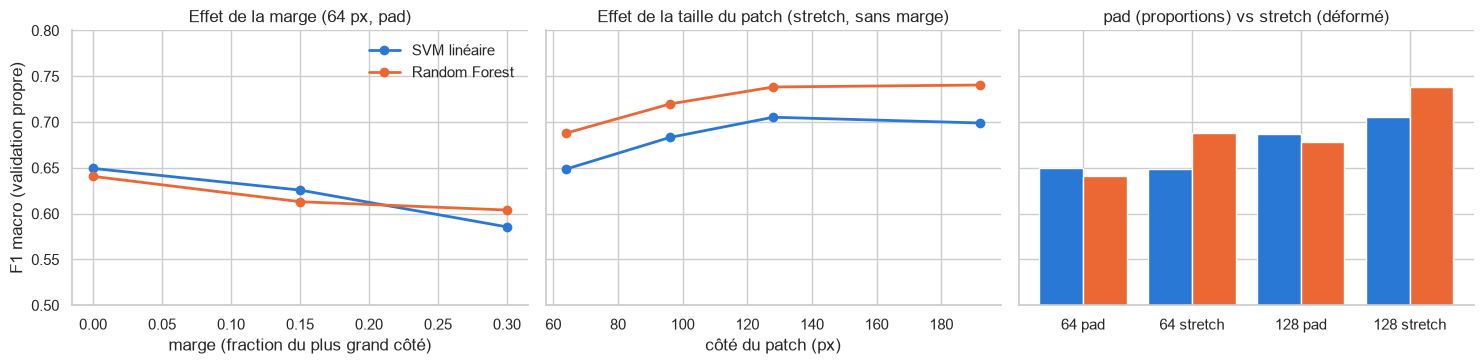

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
sel = pre_res[(pre_res["taille"] == 64) & (pre_res["mode"] == "pad")]
for name, col in [("SVM linéaire", "#2a78d6"), ("Random Forest", "#eb6834")]:
    axes[0].plot(sel["marge"], sel[name], "o-", lw=2, color=col, label=name)
axes[0].set_title("Effet de la marge (64 px, pad)"); axes[0].set_xlabel("marge (fraction du plus grand côté)"); axes[0].set_ylabel("F1 macro (validation propre)")
sel = pre_res[(pre_res["marge"] == 0) & (pre_res["mode"] == "stretch")]
for name, col in [("SVM linéaire", "#2a78d6"), ("Random Forest", "#eb6834")]:
    axes[1].plot(sel["taille"], sel[name], "o-", lw=2, color=col, label=name)
axes[1].set_title("Effet de la taille du patch (stretch, sans marge)"); axes[1].set_xlabel("côté du patch (px)")
sel = pre_res[(pre_res["marge"] == 0) & pre_res["taille"].isin([64, 128])].sort_values(["taille", "mode"])
lab = sel["taille"].astype(str) + " " + sel["mode"]
x = np.arange(len(sel))
axes[2].bar(x - 0.2, sel["SVM linéaire"], 0.4, color="#2a78d6", label="SVM linéaire")
axes[2].bar(x + 0.2, sel["Random Forest"], 0.4, color="#eb6834", label="Random Forest")
axes[2].set_xticks(x, lab); axes[2].set_title("pad (proportions) vs stretch (déformé)")
axes[0].legend(frameon=False); axes[2].set_ylim(0.5, 0.8)
plt.tight_layout(); plt.show()

**Interprétation.**
- **Marge** : contrairement à notre hypothèse de la phase 2, ajouter du contexte autour de la bbox **dégrade** le résultat. Le contexte (carrosserie intacte,
  autres dommages voisins) dilue le signal du dommage lui-même. On retient **aucune marge** : le modèle apprend sur la zone exacte du dommage.
  *Conséquence pour l'application : l'utilisateur devra recadrer **au plus près** du dommage.*
- **Taille** : passer de 64 à 128 px améliore nettement les deux sondes (les fissures fines et les rayures gardent leurs détails, utiles à la texture) ;
  192 px n'apporte plus rien et coûte deux fois plus de calcul. On retient **128 px**.
- **pad ou stretch** : à 128 px, déformer le patch donne de meilleurs résultats que garder les proportions. On retient **stretch**.
- Les écarts de 0,01 à 0,02 restent dans la marge d'incertitude d'une validation de ≈ 1 700 régions ; les décisions s'appuient sur les tendances
  confirmées par les deux sondes.

## 5. Quels descripteurs garder ?

Le cahier des charges demande de n'ajouter la couleur et la texture **que si elles améliorent le modèle**. On compare toutes les combinaisons de blocs
avec la configuration retenue.

,blocs,dimension,SVM linéaire,Random Forest,moyenne
0,hog,1764,0.581,0.663,0.622
1,color,40,0.355,0.488,0.421
2,texture,36,0.560,0.612,0.586
3,color + texture,76,0.620,0.680,0.650
4,hog + color,1804,0.627,0.719,0.673
5,hog + texture,1800,0.673,0.707,0.690
6,hog + color + texture,1840,0.705,0.738,0.722


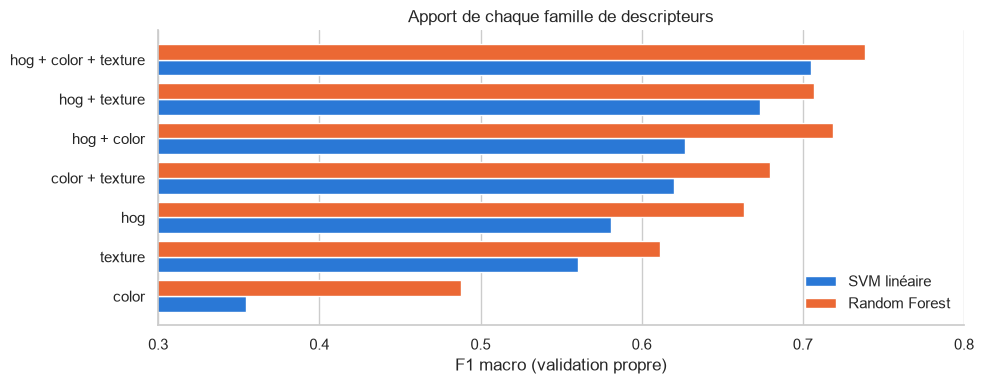

In [7]:
combos = [("hog",), ("color",), ("texture",), ("color", "texture"), ("hog", "color"), ("hog", "texture"), ("hog", "color", "texture")]
rows = []
for combo in combos:
    res = evaluate(np.hstack([blocks[b] for b in combo]))
    rows.append({"blocs": " + ".join(combo), "dimension": sum(blocks[b].shape[1] for b in combo), **res})
blk = pd.DataFrame(rows)
blk["moyenne"] = blk[["SVM linéaire", "Random Forest"]].mean(axis=1)
display(blk.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
order = blk.sort_values("moyenne")
yy = np.arange(len(order))
ax.barh(yy - 0.2, order["SVM linéaire"], 0.4, color="#2a78d6", label="SVM linéaire")
ax.barh(yy + 0.2, order["Random Forest"], 0.4, color="#eb6834", label="Random Forest")
ax.set_yticks(yy, order["blocs"]); ax.set_xlabel("F1 macro (validation propre)"); ax.set_xlim(0.3, 0.8)
ax.set_title("Apport de chaque famille de descripteurs"); ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Interprétation.**
- **HOG** est le meilleur bloc isolé (la forme du dommage est l'information principale), mais il ne suffit pas.
- La **texture** (36 valeurs seulement) améliore nettement HOG avec les deux sondes : elle capte la différence entre surface lisse, rayée, fissurée ou éclatée.
- La **couleur** seule est faible (la couleur de la carrosserie ne dit pas grand-chose du type de dommage), mais elle **apporte encore un gain** quand elle est
  ajoutée à HOG et texture (verre bleuté du pare-brise, caoutchouc noir du pneu, plastique rouge ou orange des feux).
- Remarque : couleur + texture, avec seulement **76 valeurs**, fait déjà aussi bien ou mieux que HOG seul (1764 valeurs) : les descripteurs compacts sont très informatifs.
- **Décision : on garde les trois blocs (1840 dimensions)**, la meilleure combinaison pour les deux sondes.

## 6. Encodages, normalisation, PCA, discrétisation : lesquels sont pertinents ?

Chaque technique est examinée par rapport aux **caractéristiques réelles** de nos données : 1840 variables **numériques continues**, aucune variable
catégorielle en entrée, une cible à 6 classes.

In [8]:
le = LabelEncoder().fit(CLASS_ORDER)
print("Label Encoding de y :", dict(zip(le.classes_, le.transform(le.classes_))))
print()
for b, v in blocks.items():
    print(f"{b:8s} plage sur le train : [{v[TRAIN].min():.3f}, {v[TRAIN].max():.3f}]   écart-type moyen : {v[TRAIN].std(axis=0).mean():.4f}")
tex = blocks["texture"][TRAIN]
print(f"\nExemple : contraste GLCM (distance 3) jusqu'à {tex[:, 29].max():.1f}, alors que les histogrammes sont dans [0, 1]")
print("Variables constantes sur le train :", int((X[TRAIN].std(axis=0) == 0).sum()))

Label Encoding de y : {np.str_('crack'): np.int64(0), np.str_('dent'): np.int64(1), np.str_('glass shatter'): np.int64(2), np.str_('lamp broken'): np.int64(3), np.str_('scratch'): np.int64(4), np.str_('tire flat'): np.int64(5)}

hog      plage sur le train : [0.000, 1.000]   écart-type moyen : 0.1007
color    plage sur le train : [0.000, 1.000]   écart-type moyen : 0.1123
texture  plage sur le train : [0.000, 68.049]   écart-type moyen : 0.3947

Exemple : contraste GLCM (distance 3) jusqu'à 68.0, alors que les histogrammes sont dans [0, 1]
Variables constantes sur le train : 0


,F1 macro KNN (k=5)
sans normalisation,0.501
StandardScaler,0.508
MinMaxScaler,0.496


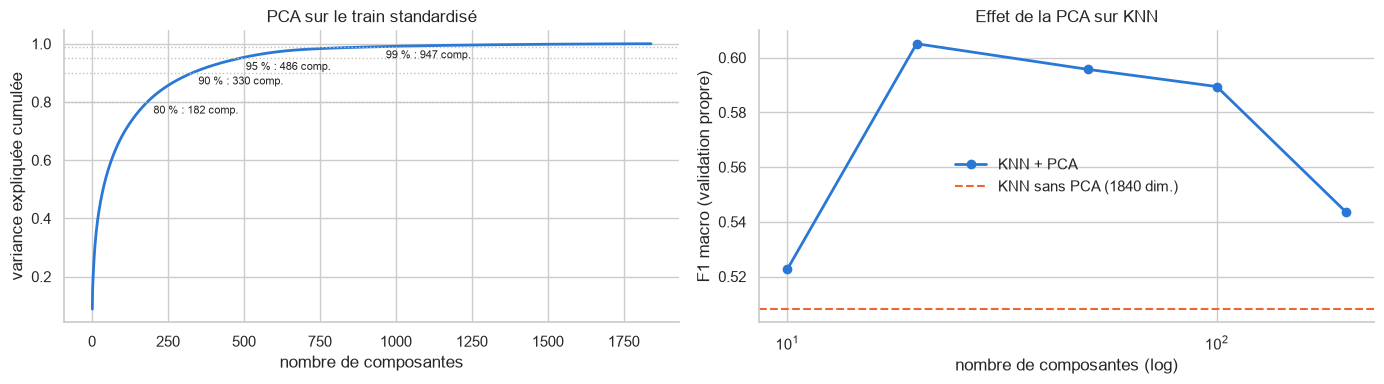

Composantes nécessaires : {0.8: 182, 0.9: 330, 0.95: 486, 0.99: 947}


In [9]:
def knn_f1(pipe):
    return f1_score(y[VAL], pipe.fit(X[TRAIN], y[TRAIN]).predict(X[VAL]), average="macro")

K = lambda: KNeighborsClassifier(5, n_jobs=-1)
scal = pd.Series({"sans normalisation": knn_f1(make_pipeline(K())),
                  "StandardScaler": knn_f1(make_pipeline(StandardScaler(), K())),
                  "MinMaxScaler": knn_f1(make_pipeline(MinMaxScaler(), K()))}, name="F1 macro KNN (k=5)")
display(scal.round(3).to_frame())

pca_full = PCA().fit(StandardScaler().fit_transform(X[TRAIN]))
cum = np.cumsum(pca_full.explained_variance_ratio_)
needed = {q: int(np.searchsorted(cum, q) + 1) for q in (0.80, 0.90, 0.95, 0.99)}
pca_res = pd.Series({n: knn_f1(make_pipeline(StandardScaler(), PCA(n, random_state=0), K())) for n in (10, 20, 50, 100, 200)})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(np.arange(1, len(cum) + 1), cum, color="#2a78d6", lw=2)
for q, n in needed.items():
    axes[0].axhline(q, color="#c3c2b7", lw=1, ls=":"); axes[0].text(n + 20, q - 0.04, f"{int(q*100)} % : {n} comp.", fontsize=8)
axes[0].set_xlabel("nombre de composantes"); axes[0].set_ylabel("variance expliquée cumulée"); axes[0].set_title("PCA sur le train standardisé")
axes[1].plot(pca_res.index, pca_res.values, "o-", color="#2a78d6", lw=2, label="KNN + PCA")
axes[1].axhline(scal["StandardScaler"], color="#eb6834", ls="--", label="KNN sans PCA (1840 dim.)")
axes[1].set_xscale("log"); axes[1].set_xlabel("nombre de composantes (log)"); axes[1].set_ylabel("F1 macro (validation propre)")
axes[1].set_title("Effet de la PCA sur KNN"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print("Composantes nécessaires :", needed)

**Décisions et justifications**

| Technique | Décision | Justification sur NOS données |
|---|---|---|
| **Label Encoding** | ✅ pour la cible *y* | 6 classes → entiers 0..5 (ordre alphabétique fixe, sauvegardé avec le modèle). Les classifieurs scikit-learn acceptent aussi les chaînes ; l'encodeur garantit la même correspondance dans l'API. Pas d'ordre implicite : un classifieur ne traite pas l'étiquette comme une grandeur. |
| **One-Hot Encoding** | ❌ | Il sert à transformer des **variables d'entrée catégorielles**. Nos 1840 variables sont toutes numériques. Encoder *y* en one-hot est inutile pour KNN, SVM et Random Forest. |
| **Leave-One-Out Encoding** | ❌ | Encodage d'une variable catégorielle à **nombreuses modalités** par la moyenne de la cible. Nous n'avons aucune variable de ce type ; l'appliquer (par exemple à la couleur du véhicule) ferait entrer la cible dans les entrées et créerait une fuite. De plus, la couleur n'est pas disponible dans l'application. |
| **StandardScaler** | ✅ | Les échelles sont très différentes (histogrammes dans [0, 1], contraste GLCM jusqu'à plusieurs dizaines). Indispensable pour le **SVM** (distances, marges) et avant la **PCA** (sinon les variables à grande variance dominent). Ajusté **sur le train uniquement**, dans le pipeline. |
| **MinMaxScaler** | ❌ | Ne fait pas mieux sur KNN et est **sensible aux valeurs extrêmes** (un seul contraste GLCM très élevé écrase toutes les autres valeurs de la colonne vers 0). |
| **PCA** | ⚠️ à tester en phase 4 | 1840 dimensions pour ≈ 6 200 exemples : KNN souffre de la **malédiction de la dimension** et profite nettement de la PCA (voir graphique). Pour SVM et Random Forest, l'intérêt est à mesurer. La PCA sera donc une **option du pipeline**, et son nombre de composantes un hyperparamètre choisi sur la validation. |
| **Discrétisation** | ❌ | Nos variables sont déjà des **histogrammes** (fréquences continues). Les découper en intervalles ferait perdre de l'information sans bénéfice ; Random Forest découpe déjà lui-même les variables en seuils. |
| **Suppression de variables constantes** | ❌ inutile | Aucune variable n'est constante sur le train. |

**Remarque :** HOG représente 1764 des 1840 dimensions. Dans une distance euclidienne (KNN), il pèse donc beaucoup plus que la couleur et la texture.
La standardisation suivie de la PCA atténue ce déséquilibre ; c'est une des raisons pour lesquelles la PCA aide autant KNN.

**Prévention des fuites de données :** l'extraction des descripteurs n'apprend rien. La normalisation et la PCA, qui apprennent des moyennes et des axes,
seront placées dans un `Pipeline` scikit-learn et ajustées **uniquement sur le train**, puis appliquées telles quelles à la validation, au test et à l'API.

## 7. Synthèse

In [10]:
summary = pd.DataFrame({
    "régions": meta.groupby("split").size(),
    "dont évaluation propre": meta[meta["image_eval_keep"]].groupby("split").size(),
}).loc[["train", "val", "test"]]
summary["dimension de X"] = X.shape[1]
display(summary)
print("Fichier de descripteurs retenu :", path.relative_to(PROJECT_ROOT))
print("Configuration de prétraitement :", configs["preprocess"])

,régions,dont évaluation propre,dimension de X
split,,,
train,6211,6211,1840
val,1744,1666,1840
test,785,761,1840


Fichier de descripteurs retenu : data\processed\features_s128_m00_stretch.npz
Configuration de prétraitement : {'patch_size': 128, 'margin': 0.0, 'resize_mode': 'stretch'}


**Pipeline de transformation retenu**

```
photo ─► découpe de la bbox (sans marge) ─► patch 128×128 (stretch) ─► HOG (1764) + couleur (40) + texture (36) ─► X : 1840 valeurs
y : nom de la classe ─► LabelEncoder (6 classes)
dans le pipeline de la phase 4 : StandardScaler (ajusté sur le train) ─► [PCA optionnelle] ─► KNN / SVM / Random Forest
```

- Choix mesurés sur la validation propre, jamais sur le test : **128 px**, **sans marge**, **stretch**, **les 3 familles de descripteurs**.
- Les sondes atteignent un F1 macro d'environ 0,70 à 0,74 sur la validation, contre 0,58 à 0,66 avec HOG seul (section 5).
- Le grand écart entre le score d'entraînement et celui de validation des sondes signale un **surapprentissage** à corriger par le réglage des hyperparamètres (phase 4).
- **Pour l'application** : la même fonction `preprocess_region` sera appelée par l'API sur la zone recadrée par l'utilisateur, qui devra recadrer **au plus près** du dommage.